In [1]:
import sys
print(sys.executable)

c:\Users\DELL\Downloads\Mauricio\UPC\Ciclos\Ciclo 14 2602\Data Science\GroundWork\.venv\Scripts\python.exe


In [2]:
import yfinance as yf
import pandas as pd
import requests
from bs4 import BeautifulSoup

In [3]:
tesla = yf.Ticker("TSLA")

In [4]:
tesla_data = tesla.history(period="max")

c:\Users\DELL\Downloads\Mauricio\UPC\Ciclos\Ciclo 14 2602\Data Science\GroundWork\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\DELL\Downloads\Mauricio\UPC\Ciclos\Ciclo 14 2602\Data Science\GroundWork\.venv\Lib\site-packages\yfinance\utils.py:604: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  splits.set_index("date", inplace=True)
c:\Users\DELL\Downloads\Mauricio\UPC\Ciclos\Ciclo 14 2602\Data Science\GroundWork\.venv\Lib\site-packages\yfinance\utils.py:606: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed i

In [5]:
tesla_data.reset_index(inplace=True)
tesla_data.head()

C:\Users\DELL\AppData\Local\Temp\ipykernel_11492\3012578559.py:1: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  tesla_data.reset_index(inplace=True)


,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2010-06-29 00:00:00-04:00,1.266667,1.666667,1.169333,1.592667,281494500,0.0,0.0
1,2010-06-30 00:00:00-04:00,1.719333,2.028000,1.553333,1.588667,257806500,0.0,0.0
2,2010-07-01 00:00:00-04:00,1.666667,1.728000,1.351333,1.464000,123282000,0.0,0.0
3,2010-07-02 00:00:00-04:00,1.533333,1.540000,1.247333,1.280000,77097000,0.0,0.0
4,2010-07-06 00:00:00-04:00,1.333333,1.333333,1.055333,1.074000,103003500,0.0,0.0


## Question 2: Use Webscraping to Extract Tesla Revenue Data

In [6]:
url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/revenue.htm"

response = requests.get(url)
response.raise_for_status()
html_data = response.text

soup = BeautifulSoup(html_data, "html.parser")
tabla = soup.find_all("table")[1]

filas = []

for row in tabla.find_all("tr"):
    columnas = row.find_all("td")
    if len(columnas) == 2:
        filas.append([
            columnas[0].get_text(strip=True),
            columnas[1].get_text(strip=True)
        ])

tesla_revenue = pd.DataFrame(filas, columns=["Date", "Revenue"])

tesla_revenue["Revenue"] = tesla_revenue["Revenue"].str.replace(
    r"[$,]", "", regex=True
)

tesla_revenue = tesla_revenue.dropna()
tesla_revenue = tesla_revenue[
    tesla_revenue["Revenue"] != ""
].copy()

tesla_revenue.tail()

,Date,Revenue
48,2010-09-30,31
49,2010-06-30,28
50,2010-03-31,21
52,2009-09-30,46
53,2009-06-30,27


## Question 3: Use yfinance to Extract Stock Data

In [7]:
gme = yf.Ticker("GME")
gme_data = gme.history(period="max")

gme_data.reset_index(inplace=True)
gme_data.head()

c:\Users\DELL\Downloads\Mauricio\UPC\Ciclos\Ciclo 14 2602\Data Science\GroundWork\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\DELL\Downloads\Mauricio\UPC\Ciclos\Ciclo 14 2602\Data Science\GroundWork\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\DELL\Downloads\Mauricio\UPC\Ciclos\Ciclo 14 2602\Data Science\GroundWork\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be remove

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2002-02-13 00:00:00-05:00,1.620128,1.693350,1.603296,1.691666,76216000,0.0,0.0
1,2002-02-14 00:00:00-05:00,1.712707,1.716073,1.670626,1.683250,11021600,0.0,0.0
2,2002-02-15 00:00:00-05:00,1.683250,1.687458,1.658002,1.674834,8389600,0.0,0.0
3,2002-02-19 00:00:00-05:00,1.666418,1.666418,1.578047,1.607504,7410400,0.0,0.0
4,2002-02-20 00:00:00-05:00,1.615920,1.662210,1.603296,1.662210,6892800,0.0,0.0


## Ejercicio 4 — Ingresos de GameStop

In [8]:
url_2 = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/stock.html"

response_2 = requests.get(url_2)
response_2.raise_for_status()
html_data_2 = response_2.text

soup_2 = BeautifulSoup(html_data_2, "html.parser")
tabla_gme = soup_2.find_all("table")[1]

filas_gme = []

for row in tabla_gme.find_all("tr"):
    columnas = row.find_all("td")
    if len(columnas) == 2:
        filas_gme.append([
            columnas[0].get_text(strip=True),
            columnas[1].get_text(strip=True)
        ])

gme_revenue = pd.DataFrame(
    filas_gme, columns=["Date", "Revenue"]
)

gme_revenue["Revenue"] = gme_revenue["Revenue"].str.replace(
    r"[$,]", "", regex=True
)

gme_revenue = gme_revenue.dropna()
gme_revenue = gme_revenue[
    gme_revenue["Revenue"] != ""
].copy()

gme_revenue.tail()

,Date,Revenue
57,2006-01-31,1667
58,2005-10-31,534
59,2005-07-31,416
60,2005-04-30,475
61,2005-01-31,709


### Ej 5 y 6

In [9]:
import matplotlib.pyplot as plt

def make_graph(stock_data, revenue_data, stock):
    precios = stock_data.copy()
    ingresos = revenue_data.copy()

    precios["Date"] = (
        pd.to_datetime(precios["Date"]).dt.tz_localize(None)
    )
    ingresos["Date"] = pd.to_datetime(ingresos["Date"])

    precios["Close"] = pd.to_numeric(precios["Close"])
    ingresos["Revenue"] = pd.to_numeric(ingresos["Revenue"])

    precios = precios[
        precios["Date"] <= "2021-06-14"
    ].sort_values("Date")

    ingresos = ingresos[
        ingresos["Date"] <= "2021-04-30"
    ].sort_values("Date")

    fig, axes = plt.subplots(
        2, 1, figsize=(12, 8), sharex=True
    )

    axes[0].plot(precios["Date"], precios["Close"], color="blue")
    axes[0].set_title(f"{stock} - Historical Share Price")
    axes[0].set_ylabel("Price (USD)")

    axes[1].plot(
        ingresos["Date"], ingresos["Revenue"], color="green"
    )
    axes[1].set_title(f"{stock} - Historical Revenue")
    axes[1].set_ylabel("Revenue (USD Millions)")
    axes[1].set_xlabel("Date")

    plt.tight_layout()
    plt.show()

## Question 5: Plot Tesla Stock Graph

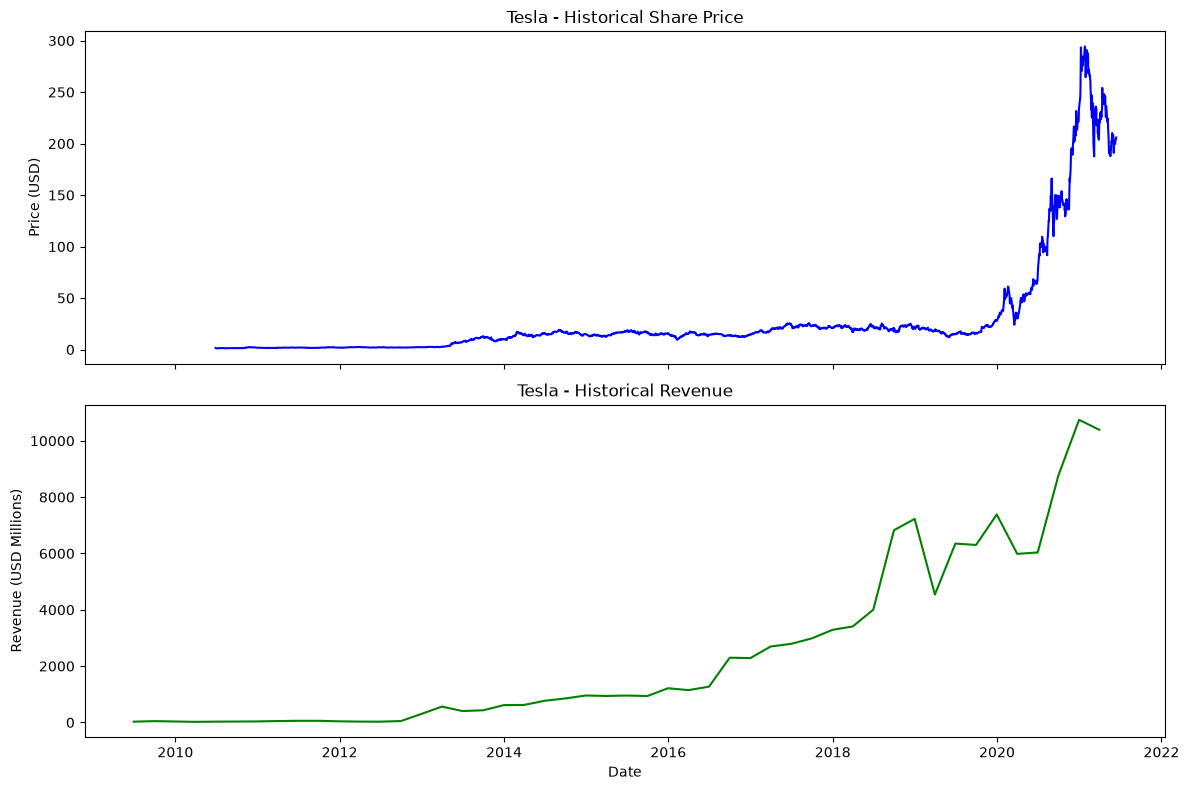

In [10]:
make_graph(tesla_data, tesla_revenue, "Tesla")

## Question 6: Plot GameStop Stock Graph

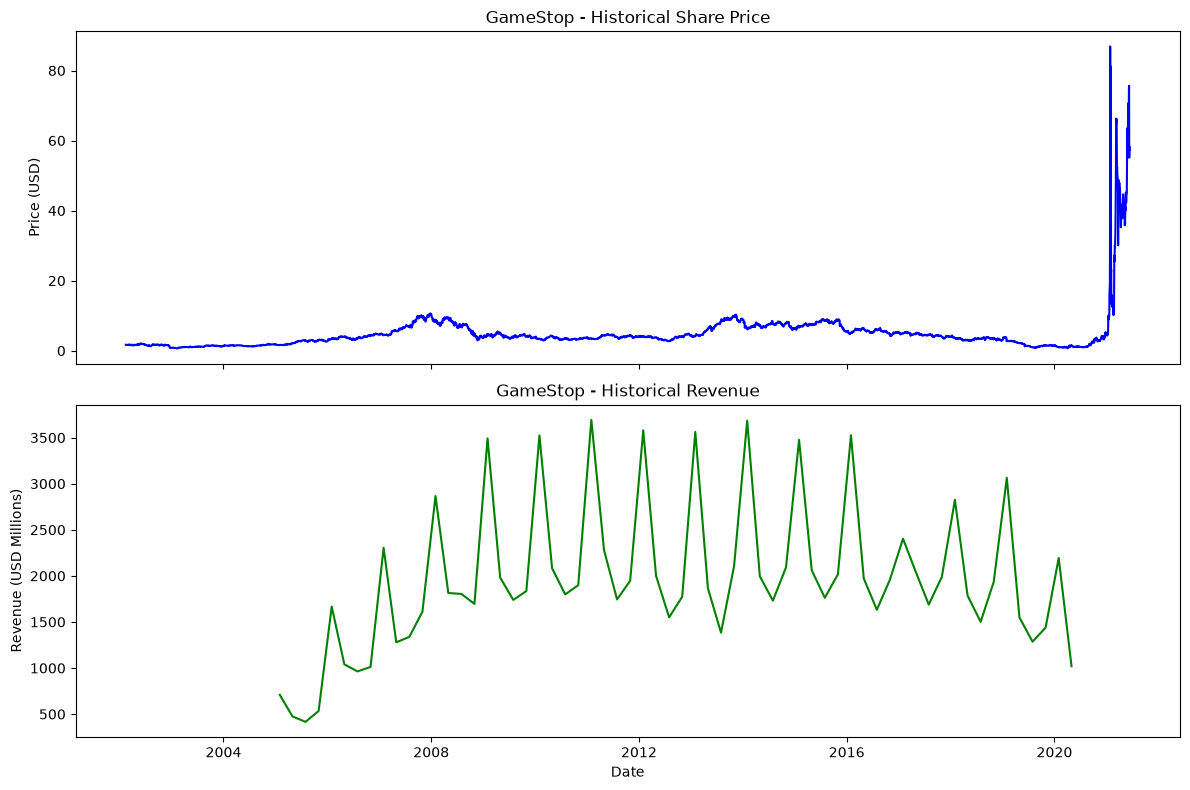

In [11]:
make_graph(gme_data, gme_revenue, "GameStop")